# Práctica 3: Simulador neuronal de CarRacing
## Semana 1: Autoencoders Convolucionales y Estudio de la Compresión
### Aprendizaje Profundo — Grado en Inteligencia Artificial
**Universidade da Coruña (UDC)**

---

### Información del Grupo de Prácticas
* **Autores:** Xoel Sánchez Dacoba y Sebastián David Moreno Expósito
* **Fecha límite de entrega:** 20 de noviembre de 2026
* **Semana de defensa individual:** 23 al 27 de noviembre de 2026
* **Objetivo de la Parte 1:** Reconstruir fotogramas individuales de $48 \times 48$ píxeles RGB sin acciones, evaluar el impacto de la compresión en el espacio latente ($d_1$ vs $d_2$), generar las particiones fijas de circuitos para toda la práctica y construir la referencia trivial de predicción (repetir último fotograma).

> **Declaración de uso de Inteligencia Artificial:**
> En cumplimiento de las instrucciones de la práctica, se declara el uso asistido de herramientas de IA (En concreto Antigravity y Claude Code) durante la fase de desarrollo e implementación del código base. Toda la experimentación, análisis de resultados y justificación teórica ha sido realizada, supervisada, contrastada y comprendida por los autores para su defensa individual presencial.

---

## Índice de Contenidos
1. [Configuración del Entorno y Reproducibilidad](#sec1)
2. [Carga y Persistencia del Dataset Fijo](#sec2)
3. [Inspección de Secuencias y Baseline Trivial (Referencia sin Entrenamiento)](#sec3)
4. [Preprocesado para el Autoencoder](#sec4)
5. [Arquitectura del Autoencoder Convolucional](#sec5)
6. [Experimento Controlado: Comparación de Espacios Latentes ($d_1=32$ vs $d_2=128$)](#sec6)
7. [Evaluación Cuantitativa y Cualitativa](#sec7)
   * 7.1. Métricas con `visual_metrics` (Score oficial, SSIM, Gradient, MSE)
   * 7.2. Paneles de Reconstrucción y Mapas de Error
   * 7.3. Interpretación y Análisis del Cuello de Botella
8. [Persistencia Modular de Modelos (.keras)](#sec8)
9. [Conclusiones](#sec9)

<a id='sec1'></a>
## 1. Configuración del Entorno y Reproducibilidad

Comprobamos la disponibilidad de aceleración hardware (GPU NVIDIA) e importamos las librerías necesarias. Fijamos las semillas aleatorias en `random`, `numpy` y `keras` para asegurar la reproducibilidad.

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'#Esto es para quitar un ruido de warnings de TensorFlow que no aportan nada útil en este caso
import sys
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

CURRENT_DIR = os.path.abspath('')# Asegurar acceso a módulos locales de la práctica
if CURRENT_DIR not in sys.path:
    sys.path.insert(0, CURRENT_DIR)

import tensorflow as tf
import keras
from keras import layers, Model

import dataset#Estos 3 son los módulos locales de la práctica
import carracing48
import metric

SEED = 77# Configuración de seeds para reproducibilidad
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

os.makedirs('data', exist_ok=True)# Creo directorios de persistencia para datos y modelos
os.makedirs('models', exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')#Pequeño check de GPU
print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__}")
print(f"Dispositivos GPU detectados: {gpus}")
if gpus:
    for gpu in gpus:
        print(f" -> GPU activa: {gpu.name}")
else:
    print("AVISO: No se detectó GPU activa.(se realizará en CPU, lo que puede ser muy lento)")

TensorFlow: 2.21.0 | Keras: 3.15.1
Dispositivos GPU detectados: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
 -> GPU activa: /physical_device:GPU:0


<a id='sec2'></a>
## 2. Carga y Persistencia del Dataset Fijo

> **Regla común obligatoria:**
> *"Separa entrenamiento y validación antes de crear ventanas: todas las ventanas de un circuito deben permanecer en la misma partición."*

Generamos los circuitos usando `dataset.generate_sequences` con semillas distintas y fijas:
* **Entrenamiento:** 128 secuencias largas (`seed=1488`).
* **Validación:** 32 secuencias largas (`seed=1314`).

Para evitar generar el dataset en cada ejecución (lo cual requiere varios minutos de simulación física en CPU), implementamos un mecanismo de caché en disco (`data/carracing_data.npz`) que persiste los datos para utilizarlos en todas las semanas de la práctica.

In [3]:
DATA_FILE = os.path.join('data', 'carracing_data.npz')
TRAIN_SEED = 1488
VAL_SEED = 1314
N_TRAIN_SEQS = 128
N_VAL_SEQS = 32

if os.path.exists(DATA_FILE):
    print(f"Cargando dataset: {DATA_FILE}...")
    cached = np.load(DATA_FILE)
    train_frames = cached['train_frames']
    train_actions = cached['train_actions']
    val_frames = cached['val_frames']
    val_actions = cached['val_actions']
    print("Dataset cargado con exito")
else:
    print(f"Archivo {DATA_FILE} no encontrado. Iniciando generación con semillas fijas...")
    
    t0 = time.time()
    print(f"Generando {N_TRAIN_SEQS} secuencias de entrenamiento (semilla {TRAIN_SEED})...")
    train_data = dataset.generate_sequences(seed=TRAIN_SEED, n_sequences=N_TRAIN_SEQS)
    print(f"Entrenamiento generado en {time.time() - t0:.1f} s.")
    
    t1 = time.time()
    print(f"Generando {N_VAL_SEQS} secuencias de validación (semilla {VAL_SEED})...")
    val_data = dataset.generate_sequences(seed=VAL_SEED, n_sequences=N_VAL_SEQS)
    print(f"Validación generada en {time.time() - t1:.1f} s.")
    
    train_frames, train_actions = train_data['frames'], train_data['actions']
    val_frames, val_actions = val_data['frames'], val_data['actions']
    
    print(f"guardando en {DATA_FILE} para reutilizar en las semanas...")
    np.savez_compressed(
        DATA_FILE,
        train_frames=train_frames,
        train_actions=train_actions,
        val_frames=val_frames,
        val_actions=val_actions,
        train_seed=TRAIN_SEED,
        val_seed=VAL_SEED
    )
    print("Guardado completado")

print("\n--- Resumen de Datos Generados ---")
print(f"Train frames shape:  {train_frames.shape}  | Dtype: {train_frames.dtype} | Min: {train_frames.min()}, Max: {train_frames.max()}")
print(f"Train actions shape: {train_actions.shape} | Dtype: {train_actions.dtype}")
print(f"Val frames shape:    {val_frames.shape}    | Dtype: {val_frames.dtype}")
print(f"Val actions shape:   {val_actions.shape}   | Dtype: {val_actions.dtype}")

Cargando dataset: data/carracing_data.npz...
Dataset cargado con exito

--- Resumen de Datos Generados ---
Train frames shape:  (128, 96, 48, 48, 3)  | Dtype: uint8 | Min: 0, Max: 253
Train actions shape: (128, 95) | Dtype: int64
Val frames shape:    (32, 96, 48, 48, 3)    | Dtype: uint8
Val actions shape:   (32, 95)   | Dtype: int64


<a id='sec3'></a>
## 3. Inspección de Secuencias y Baseline Trivial (Referencia sin Entrenamiento)

El enunciado exige:
1. **Inspeccionar una secuencia y comprobar imágenes, acciones y alineación temporal:**
   * Cada acción $a_j$ transforma el fotograma $x_j$ en $x_{j+1}$.
   * Las acciones son enteros discretos: `0 = nada`, `1 = derecha`, `2 = izquierda`, `3 = acelerar`, `4 = frenar`.
   * Cada paso de acción dura 4 pasos físicos del simulador ($0,08\text{ s}$ simulados).
2. **Crear por separado y sin entrenamiento la referencia que repite la última imagen durante 24 pasos:**
   * Este predictor trivial servirá como cota inferior obligatoria para medir el valor real de los modelos temporales posteriores.

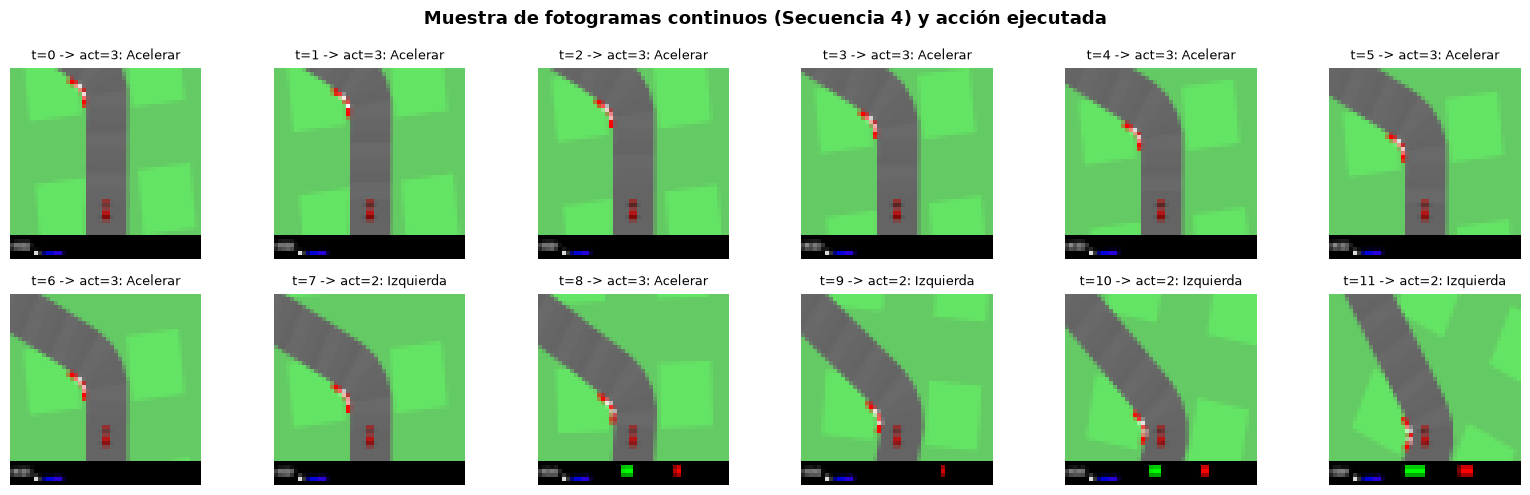

In [19]:
seq_idx = 4#Alterar este indice para inspeccionar otras secuencias de validación(numero entre 0 y 31)
action_labels = {0: '0: Nada', 1: '1: Derecha', 2: '2: Izquierda', 3: '3: Acelerar', 4: '4: Frenar'}

fig, axes = plt.subplots(2, 6, figsize=(16, 5))
fig.suptitle(f"Muestra de fotogramas continuos (Secuencia {seq_idx}) y acción ejecutada", fontsize=13, fontweight='bold')

for i, ax in enumerate(axes.flat):
    ax.imshow(val_frames[seq_idx, i])
    act = val_actions[seq_idx, i]
    ax.set_title(f"t={i} -> act={action_labels.get(act, str(act))}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [22]:
def baseline_repeat_last(context_frames, horizon=24):#Definimos un baseline trivial que repite el último fotograma observado para predecir los pasos futuros
    """
    Dada una secuencia de contexto de longitud C (..., C, 48, 48, 3),
    predice 'horizon' pasos futuros repitiendo exactamente el último fotograma observado.
    """
    last_frame = context_frames[:, -1:, ...]
    return np.repeat(last_frame, repeats=horizon, axis=1)

sample_context = val_frames[:10, :12].astype('float32') / 255.0# Prueba del baseline sobre una ventana estándar de validación (12 contexto -> 24 objetivos)
sample_targets = val_frames[:10, 12:36].astype('float32') / 255.0
sample_pred = baseline_repeat_last(sample_context, horizon=24)

baseline_eval = metric.visual_metrics(sample_targets, sample_pred)
print("Evaluación del Baseline Trivial:")
for k, v in baseline_eval.items():
    print(f"  * {k.upper():<10}: {v:.6f}")

Evaluación del Baseline Trivial:
  * SCORE     : 0.100862
  * SSIM      : 0.751435
  * GRADIENT  : 0.007179
  * MSE       : 0.015856


<a id='sec4'></a>
## 4. Preprocesado para el Autoencoder

Para entrenar el autoencoder convolucional de la Semana 1:
1. **Desacople temporal:** No usamos ventanas temporales ni recurrentes; cada fotograma es un ejemplo independiente.
2. **Aplanado de secuencias:** Convertimos $(N, 96, 48, 48, 3)$ en $(N \times 96, 48, 48, 3)$.
3. **Normalización:** Escalamos los píxeles de $[0, 255]$ a $[0.0, 1.0]$ dividiendo por $255.0$.
4. **Barajado (Shuffle):** Barajamos únicamente los fotogramas del conjunto de entrenamiento para romper la correlación temporal entre fotogramas consecutivos.
5. **Entrada y Objetivo idénticos:** El autoencoder aprende la función identidad sujeta a un cuello de botella: $\mathbf{x} \approx \tilde{\mathbf{x}}$.

In [25]:
X_train = train_frames.reshape(-1, 48, 48, 3).astype('float32') / 255.0# Normalización y colapso de dimensiones para entrenamiento independiente
X_val   = val_frames.reshape(-1, 48, 48, 3).astype('float32') / 255.0

indices = np.arange(len(X_train))
np.random.shuffle(indices)#ya hago shuffle de los indices para barajar los fotogramas de entrenamiento
X_train = X_train[indices]

print(f"Conjunto de entrenamiento para Autoencoder: {X_train.shape} (Rango: [{X_train.min():.2f}, {X_train.max():.2f}])")
print(f"Conjunto de validación para Autoencoder: {X_val.shape} (Rango: [{X_val.min():.2f}, {X_val.max():.2f}])")

Conjunto de entrenamiento para Autoencoder: (12288, 48, 48, 3) (Rango: [0.00, 0.99])
Conjunto de validación para Autoencoder: (3072, 48, 48, 3) (Rango: [0.00, 0.99])


<a id='sec5'></a>
## 5. Arquitectura del Autoencoder Convolucional

### Principios de diseño (Semana 1):
* **Sin conexiones residuales ni saltos (`Add`):** La arquitectura es estrictamente convolucional pura feedforward.
* **Modularidad:** Construimos explícitamente el **Codificador ($E$)** y el **Decodificador ($D$)** como modelos funcionales independientes de Keras para poder guardarlos, analizarlos y reutilizarlos desacoplados en las semanas 2, 3, 4 y 5.
* **Codificador:** Reduce la resolución espacial de $48 \times 48$ a $3 \times 3$ mediante 4 convoluciones con `strides=2`, finalizando en un aplanado (`Flatten`) y una proyección lineal al espacio latente $\mathbb{R}^d$.
* **Decodificador:** Invierte el proceso comenzando con una capa `Dense` que recupera el volumen $3 \times 3 \times 256$, seguida de 4 capas `Conv2DTranspose` con `strides=2` para recuperar $48 \times 48$. La última capa utiliza activación `sigmoid` para asegurar estrictamente que las reconstrucciones queden en $[0, 1]$.

In [27]:
def build_encoder(latent_dim, name=None):
    """Construye el Codificador E: (48, 48, 3) -> (d,)"""
    inputs = layers.Input(shape=(48, 48, 3), name='encoder_input')
    
    # Reducción espacial progresiva: 48x48 -> 24x24 -> 12x12 -> 6x6 -> 3x3
    x = layers.Conv2D(32, kernel_size=3, strides=2, padding='same', activation='relu', name='enc_conv1')(inputs)
    x = layers.Conv2D(64, kernel_size=3, strides=2, padding='same', activation='relu', name='enc_conv2')(x)
    x = layers.Conv2D(128, kernel_size=3, strides=2, padding='same', activation='relu', name='enc_conv3')(x)
    x = layers.Conv2D(256, kernel_size=3, strides=2, padding='same', activation='relu', name='enc_conv4')(x)
    
    x = layers.Flatten(name='enc_flatten')(x)
    latent = layers.Dense(latent_dim, activation=None, name='latent_code')(x)
    model_name = name or f"encoder_d{latent_dim}"
    return Model(inputs=inputs, outputs=latent, name=model_name)

def build_decoder(latent_dim, name=None):
    """Construye el Decodificador D: (d,) -> (48, 48, 3)"""
    inputs = layers.Input(shape=(latent_dim,), name='decoder_input')
    
    # Proyección lineal y reconstrucción del volumen base 3x3x256
    x = layers.Dense(3 * 3 * 256, activation='relu', name='dec_dense')(inputs)
    x = layers.Reshape((3, 3, 256), name='dec_reshape')(x)
    
    # Expansión espacial progresiva: 3x3 -> 6x6 -> 12x12 -> 24x24 -> 48x48(Creando este efecto hablado en clase de simetría invertida)
    x = layers.Conv2DTranspose(128, kernel_size=3, strides=2, padding='same', activation='relu', name='dec_deconv1')(x)
    x = layers.Conv2DTranspose(64, kernel_size=3, strides=2, padding='same', activation='relu', name='dec_deconv2')(x)
    x = layers.Conv2DTranspose(32, kernel_size=3, strides=2, padding='same', activation='relu', name='dec_deconv3')(x)
    outputs = layers.Conv2DTranspose(3, kernel_size=3, strides=2, padding='same', activation='sigmoid', name='dec_output')(x)
    
    model_name = name or f"decoder_d{latent_dim}"
    return Model(inputs=inputs, outputs=outputs, name=model_name)

def build_autoencoder(latent_dim):
    """Construye y enlaza el Autoencoder completo AE = D(E(x))"""
    encoder = build_encoder(latent_dim)
    decoder = build_decoder(latent_dim)
    
    inputs = encoder.input
    reconstructed = decoder(encoder.output)
    ae = Model(inputs=inputs, outputs=reconstructed, name=f"autoencoder_d{latent_dim}")
    return encoder, decoder, ae

In [28]:
enc_sample, dec_sample, ae_sample = build_autoencoder(32)
print("=== RESUMEN DEL CODIFICADOR (d=32) ===")
enc_sample.summary()
print("\n=== RESUMEN DEL DECODIFICADOR (d=32) ===")
dec_sample.summary()

I0000 00:00:1794849397.439418    7071 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4045 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:08:00.0, compute capability: 7.5


=== RESUMEN DEL CODIFICADOR (d=32) ===


Model: "encoder_d32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1 (Conv2D)              │ (None, 24, 24, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv3 (Conv2D)              │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv4 (Conv2D)              │ (None, 3, 3, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_flatten (Flatten)           │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_code (Dense)             │ (None, 32)             │        73,760 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462,176 (1.76 MB)

 Trainable params: 462,176 (1.76 MB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense (Dense)               │ (None, 2304)           │        76,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_reshape (Reshape)           │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv1 (Conv2DTranspose)   │ (None, 6, 6, 128)      │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv2 (Conv2DTranspose)   │ (None, 12, 12, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv3 (Conv2DTranspose)   │ (None, 24, 24, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_output (Conv2DTranspose)    │ (None, 48, 48, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 464,195 (1.77 MB)

 Trainable params: 464,195 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

<a id='sec6'></a>
## 6. Experimento Controlado: Comparación de Espacios Latentes ($d_1=32$ vs $d_2=128$)

> **Requisito del enunciado:**
> *"Entrena un autoencoder convolucional sin conexiones residuales. Compara dos tamaños del espacio latente manteniendo el resto del experimento constante."*

Seleccionamos:
* **Modelo A:** $d_1 = 32$ (Factor de compresión $\approx 216:1$).
* **Modelo B:** $d_2 = 128$ (Factor de compresión $\approx 54:1$).

**Condiciones idénticas estrictas:**
* Optimizador: `Adam(learning_rate=1e-3)`
* Pérdida: `mse`
* Batch size: 64
* Épocas: 20 con `EarlyStopping(patience=5, restore_best_weights=True)`
* Mismos conjuntos de datos normalizados (`X_train`, `X_val`)

In [29]:
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3

def train_ae_variant(latent_dim):
    print(f"\n{'='*55}")
    print(f" INICIANDO ENTRENAMIENTO: ESPACIO LATENTE d = {latent_dim}")
    print(f"{'='*55}")
    
    encoder, decoder, ae = build_autoencoder(latent_dim)
    ae.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='mse'
    )
    
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True,
            verbose=1
        )
    ]
    
    t_start = time.time()
    history = ae.fit(
        X_train, X_train,
        validation_data=(X_val, X_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )
    elapsed = time.time() - t_start
    print(f"Entrenamiento d={latent_dim} completado en {elapsed:.1f} segundos.")
    
    return {
        'latent_dim': latent_dim,
        'encoder': encoder,
        'decoder': decoder,
        'ae': ae,
        'history': history,
        'time': elapsed,
        'total_params': ae.count_params()
    }

In [30]:
# Entrenamiento de la Variante 1 (d = 32)
result_d32 = train_ae_variant(32)


 INICIANDO ENTRENAMIENTO: ESPACIO LATENTE d = 32
Epoch 1/20


I0000 00:00:1794849776.904215   11938 service.cc:153] XLA service 0x764cc8059640 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794849776.904249   11938 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2060, Compute Capability 7.5 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794849776.947575   11938 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794849777.317949   11938 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1794849777.330063   11938 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3579__.13


  5/192 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0598 

I0000 00:00:1794849782.596573   11938 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


192/192 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - loss: 0.0162 - val_loss: 0.0049
Epoch 2/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0030 - val_loss: 0.0023
Epoch 3/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0020 - val_loss: 0.0017
Epoch 4/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0015 - val_loss: 0.0013
Epoch 5/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 6/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 7/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 8/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 9.9789e-04 - val_loss: 9.8456e-04
Epoch 9/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 9.4757e-04 - val_loss: 9.3505e-04
Epoch 10/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 8.9030e-04 - val_loss: 8.8541e-04
Epoch 11/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 8.3856e-04 - val_loss: 8.4896e-04
Epoch 12/20
192/192

In [31]:
# Entrenamiento de la Variante 2 (d = 128)
result_d128 = train_ae_variant(128)


 INICIANDO ENTRENAMIENTO: ESPACIO LATENTE d = 128
Epoch 1/20


I0000 00:00:1794849851.364409   11941 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22879__.13


192/192 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.0154 - val_loss: 0.0039
Epoch 2/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0026 - val_loss: 0.0020
Epoch 3/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 4/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 5/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 6/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0010 - val_loss: 9.7762e-04
Epoch 7/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 9.3329e-04 - val_loss: 8.9952e-04
Epoch 8/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 8.7399e-04 - val_loss: 8.7333e-04
Epoch 9/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 8.2156e-04 - val_loss: 8.2842e-04
Epoch 10/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 7.8771e-04 - val_loss: 7.7950e-04
Epoch 11/20
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 7.5986e-04 - val_loss: 7.4879e-04
Epoch 12

Error final de entrenamiento (d=32): 0.00065431
Error final de validacion (d=32): 0.00069293
Error final de entrenamiento (d=128): 0.00060380
Error final de validacion (d=128): 0.00065795
Diferencia de error final entre variantes(en validacion):  0.00003498


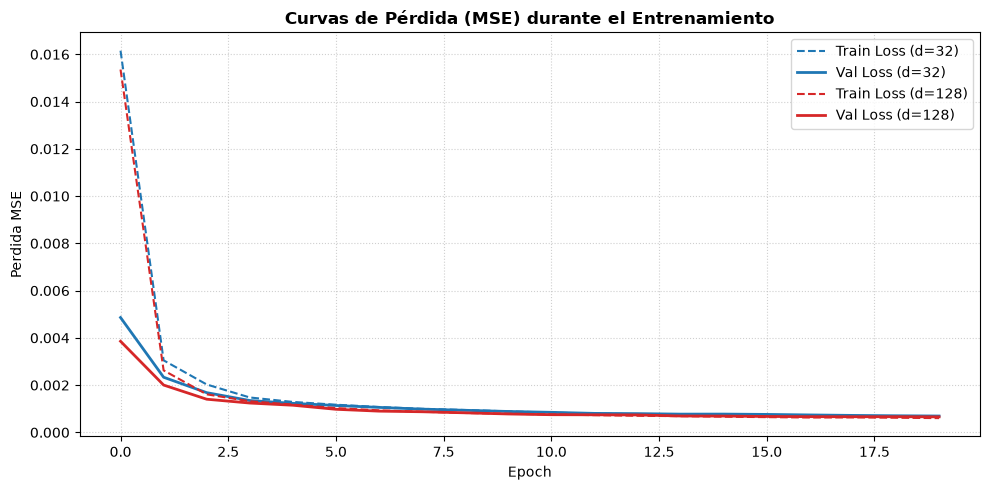

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(result_d32['history'].history['loss'], label='Train Loss (d=32)', color='#1f77b4', linestyle='--')
plt.plot(result_d32['history'].history['val_loss'], label='Val Loss (d=32)', color='#1f77b4', linewidth=2)
plt.plot(result_d128['history'].history['loss'], label='Train Loss (d=128)', color='#d62728', linestyle='--')
plt.plot(result_d128['history'].history['val_loss'], label='Val Loss (d=128)', color='#d62728', linewidth=2)

print("Error final de entrenamiento (d=32):", f"{result_d32['history'].history['loss'][-1]:.8f}")
print("Error final de validacion (d=32):", f"{result_d32['history'].history['val_loss'][-1]:.8f}")
print("Error final de entrenamiento (d=128):", f"{result_d128['history'].history['loss'][-1]:.8f}")
print("Error final de validacion (d=128):", f"{result_d128['history'].history['val_loss'][-1]:.8f}")
print("Diferencia de error final entre variantes(en validacion): ", f"{result_d32['history'].history['val_loss'][-1] - result_d128['history'].history['val_loss'][-1]:.8f}")
plt.title('Curvas de Pérdida (MSE) durante el Entrenamiento', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Perdida MSE')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


<a id='sec7'></a>
## 7. Evaluación Cuantitativa y Cualitativa

### 7.1. Métricas con metric.visual_metrics
Evaluamos cuantitativamente ambos autoencoders sobre el conjunto completo de validación utilizando la métrica oficial de la competición:
* **Score Oficial:** $S = 0.8 \cdot \frac{1 - \text{SSIM}}{2} + 0.2 \cdot G$ (menor es mejor; 0 es reconstrucción perfecta).
* **SSIM:** Similitud estructural promediando canales RGB.
* **Gradient MAE ($G$):** Error absoluto en gradientes espaciales (preservación de bordes).
* **MSE:** Error cuadrático medio pixel a pixel.

In [ ]:
rec_val_d32  = result_d32['ae'].predict(X_val, batch_size=BATCH_SIZE, verbose=0)#Con el .predict() obtengo las reconstrucciones de los fotogramas de validación usando el autoencoder entrenado
rec_val_d128 = result_d128['ae'].predict(X_val, batch_size=BATCH_SIZE, verbose=0)
rec_val_d32  = np.clip(rec_val_d32, 0.0, 1.0)#con clip corto los valores de las reconstrucciones para que estén estrictamente en el rango [0, 1]
rec_val_d128 = np.clip(rec_val_d128, 0.0, 1.0)
metrics_d32  = metric.visual_metrics(X_val, rec_val_d32)
metrics_d128 = metric.visual_metrics(X_val, rec_val_d128)

# Tabla comparativa formateada
df_results = pd.DataFrame([
    {
        'Modelo': 'Autoencoder (d=32)',
        'Latente (d)': 32,
        'Compresión': f"{48*48*3 / 32:.1f}x",
        'Parámetros': result_d32['total_params'],
        'Tiempo (s)': f"{result_d32['time']:.1f}",
        'Val MSE': metrics_d32['mse'],
        'Val SSIM': metrics_d32['ssim'],
        'Val Gradient': metrics_d32['gradient'],
        'Kaggle Score': metrics_d32['score']
    },
    {
        'Modelo': 'Autoencoder (d=128)',
        'Latente (d)': 128,
        'Compresión': f"{48*48*3 / 128:.1f}x",
        'Parámetros': result_d128['total_params'],
        'Tiempo (s)': f"{result_d128['time']:.1f}",
        'Val MSE': metrics_d128['mse'],
        'Val SSIM': metrics_d128['ssim'],
        'Val Gradient': metrics_d128['gradient'],
        'Kaggle Score': metrics_d128['score']
    }
])

print("TABLA COMPARATIVA DE RESULTADOS")
display(df_results)#el dataframe de pandas tiene un metodo legible para mostralo

=== TABLA COMPARATIVA DE RESULTADOS ===


,Modelo,Latente (d),Compresión,Parámetros,Tiempo (s),Val MSE,Val SSIM,Val Gradient,Kaggle Score
0,Autoencoder (d=32),32,216.0x,926371,51.1,0.000693,0.928609,0.004266,0.029409
1,Autoencoder (d=128),128,54.0x,1368835,48.1,0.000658,0.934473,0.004306,0.027072


### 7.2. Paneles de Reconstrucción y Mapas de Error

Mostramos una comparativa visual lado a lado para varios fotogramas de validación:
1. Fotograma Original ($x_t$).
2. Reconstrucción con $d=32$ ($\tilde{x}_{32}$).
3. Mapa de error absoluto $|x_t - \tilde{x}_{32}|$.
4. Reconstrucción con $d=128$ ($\tilde{x}_{128}$).
5. Mapa de error absoluto $|x_t - \tilde{x}_{128}|$.

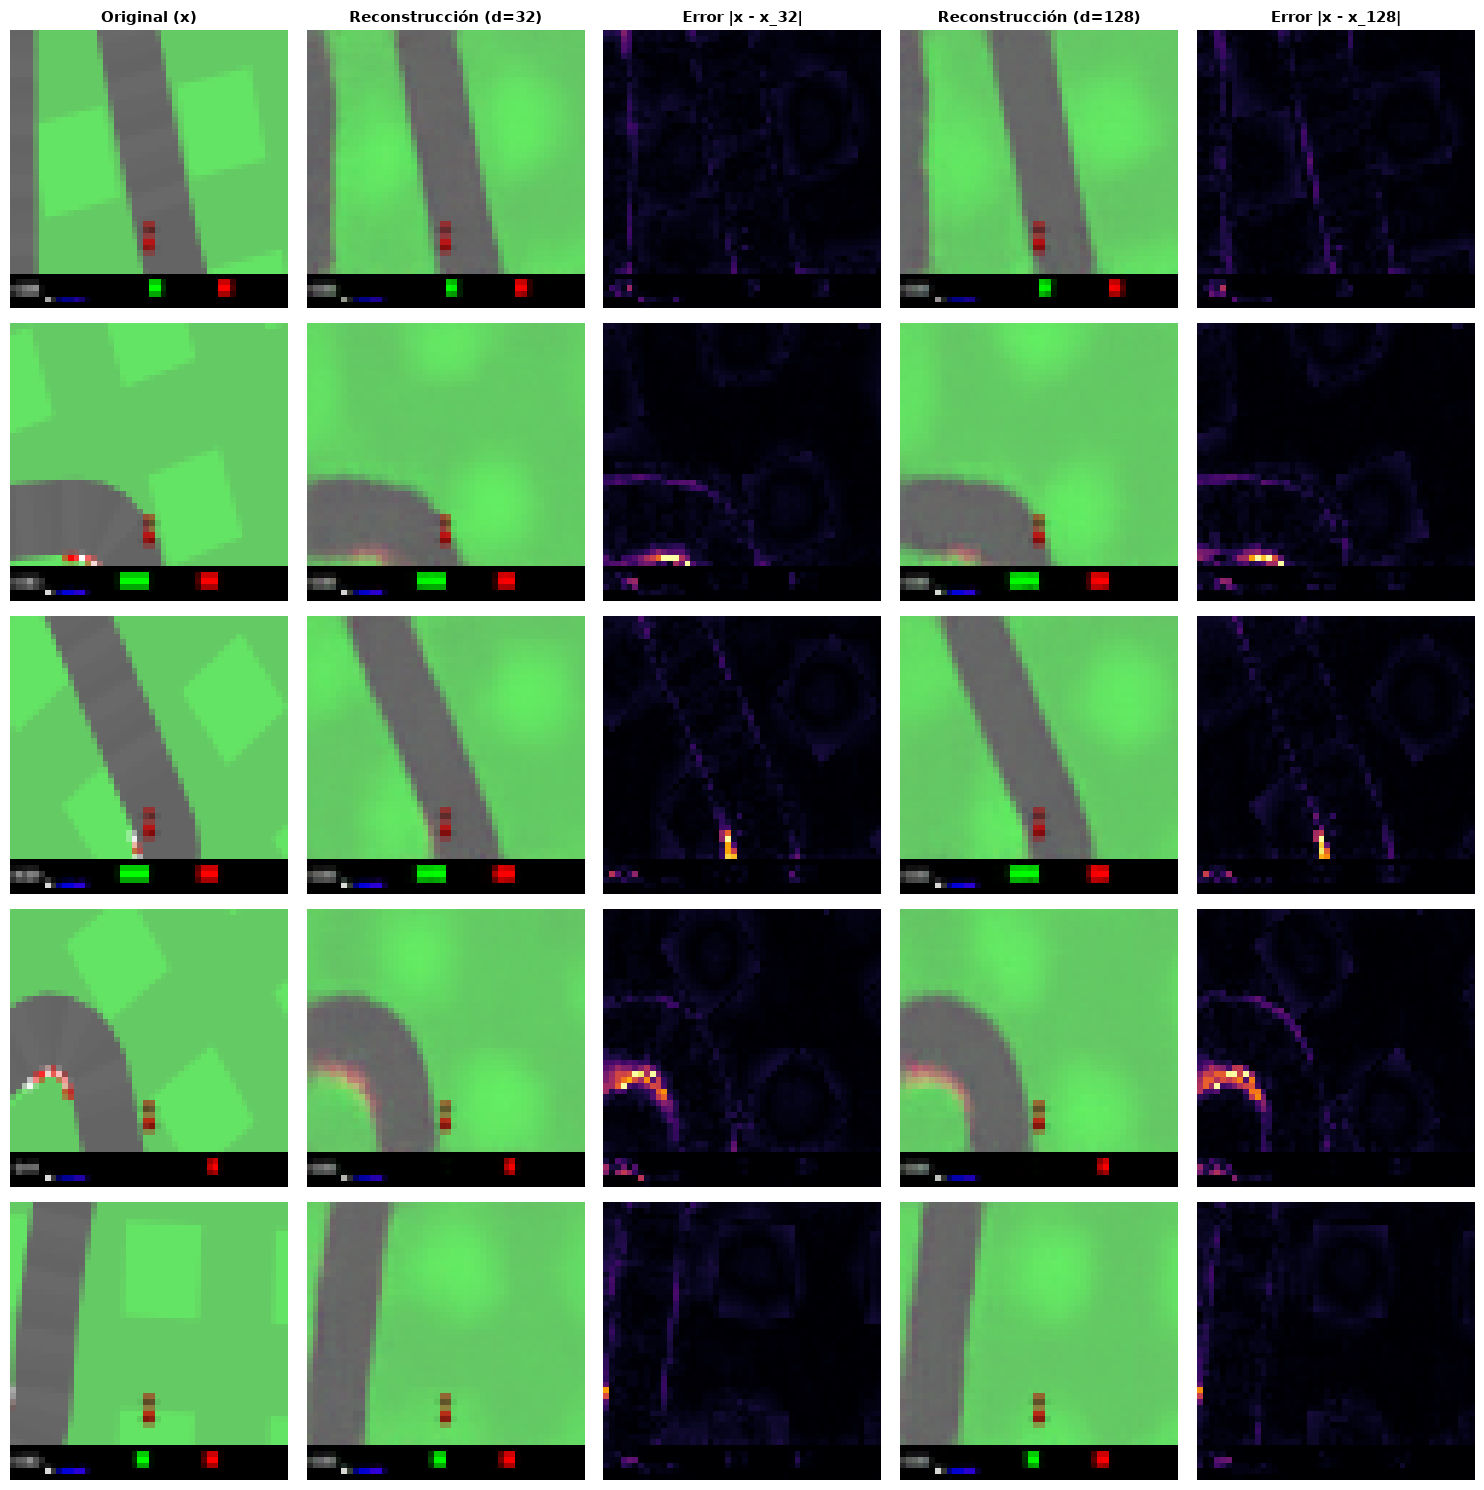

In [47]:
n_samples = 5
sample_indices = [10, 45, 100, 250, 500]

fig, axes = plt.subplots(n_samples, 5, figsize=(15, 3 * n_samples))
col_titles = [
    'Original (x)', 
    'Reconstrucción (d=32)', 
    'Error |x - x_32|',
    'Reconstrucción (d=128)', 
    'Error |x - x_128|'
]

for row, idx in enumerate(sample_indices):
    orig = X_val[idx]
    r32  = rec_val_d32[idx]
    r128 = rec_val_d128[idx]
    err32  = np.mean(np.abs(orig - r32), axis=-1)
    err128 = np.mean(np.abs(orig - r128), axis=-1)
    
    axes[row, 0].imshow(orig)
    axes[row, 1].imshow(r32)
    im_err1 = axes[row, 2].imshow(err32, cmap='inferno', vmin=0, vmax=0.3)
    axes[row, 3].imshow(r128)
    im_err2 = axes[row, 4].imshow(err128, cmap='inferno', vmin=0, vmax=0.3)
    
    if row == 0:
        for col, title in enumerate(col_titles):
            axes[row, col].set_title(title, fontsize=11, fontweight='bold')
            
    for col in range(5):
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

### 7.3. Interpretación y Análisis del Cuello de Botella

**Análisis de los resultados obtenidos:**
1. **Impacto de la dimensionalidad ($d=32$ frente a $d=128$):**
   * **Fidelidad vs. Parámetros:** Al pasar a $d=128$, el MSE en validación se reduce de $0.000693$ a $0.000658$ ($-5.1\%$), el SSIM sube de $0.9286$ a $0.9345$ y el Score de Kaggle mejora un $7.9\%$ ($0.0294 \to 0.0271$). Sin embargo, esto requiere un $+47.8\%$ más de parámetros ($926\text{k} \to 1.37\text{M}$) y cuadruplica el tamaño del vector que el futuro predictor temporal (LSTM/Transformer) deberá modelar.
   * **Bordes:** El error de gradiente ($G$, preservación de bordes) no mejora con $d=128$: es ligeramente peor ($0.004306$ frente a $0.004266$). La mejora del Score procede del SSIM, no de los bordes.
   * **Compresión:** Con $d=32$ se logra una compresión de $216\times$ con una calidad muy cercana a la de $d=128$ ($54\times$), lo que la convierte en una opción muy competitiva.
2. **Generalización (sin overfitting):**
   * En ambas variantes la diferencia entre train y val es mínima (orden de $10^{-5}$: $0.000654$ vs $0.000693$ en $d=32$; $0.000604$ vs $0.000658$ en $d=128$), lo que indica una buena generalización sobre circuitos nuevos.
   * La mejor época de ambos modelos es la última (20) y la pérdida de validación seguía bajando, así que con más épocas podrían mejorar algo.
3. **Distribución del error (mapas de 7.2):**
   * El asfalto, la hierba y el coche se reconstruyen con error casi nulo.
   * El error se concentra en los detalles de alta frecuencia: sobre todo en los bordillos rojos y blancos de las curvas, y en menor medida en los contornos de los cuadrados de hierba, que ambos modelos emborronan. Visualmente, las diferencias entre $d=32$ y $d=128$ son pequeñas.
4. **Tiempo de entrenamiento:** $51.1$ s ($d=32$) frente a $48.1$ s ($d=128$). La diferencia no se debe al tamaño del latente: la primera época de $d=32$ incluye la compilación XLA inicial ($11$ s frente a $7$ s), y el resto de épocas cuestan lo mismo ($\approx 2$ s).


<a id='sec8'></a>
## 8. Persistencia Modular de Modelos (.keras)

> **Requisito del enunciado:**
> *"Conserva codificador y decodificador para reutilizarlos por separado. Guarda los modelos en formato `.keras`."*

Guardamos en la carpeta `models/`:
* Los codificadores individuales: `encoder_d32.keras` y `encoder_d128.keras`.
* Los decodificadores individuales: `decoder_d32.keras` y `decoder_d128.keras`.
* Los autoencoders completos: `autoencoder_d32.keras` y `autoencoder_d128.keras`.

Comprobamos asimismo que pueden cargarse e inferirse de forma aislada sin dependencias de estado.

In [48]:
# Guardado de modelos en formato .keras nativo
paths = {
    'enc_d32': os.path.join('models', 'encoder_d32.keras'),
    'dec_d32': os.path.join('models', 'decoder_d32.keras'),
    'ae_d32':  os.path.join('models', 'autoencoder_d32.keras'),
    'enc_d128': os.path.join('models', 'encoder_d128.keras'),
    'dec_d128': os.path.join('models', 'decoder_d128.keras'),
    'ae_d128':  os.path.join('models', 'autoencoder_d128.keras')
}

result_d32['encoder'].save(paths['enc_d32'])
result_d32['decoder'].save(paths['dec_d32'])
result_d32['ae'].save(paths['ae_d32'])

result_d128['encoder'].save(paths['enc_d128'])
result_d128['decoder'].save(paths['dec_d128'])
result_d128['ae'].save(paths['ae_d128'])

print("Modelos guardados exitosamente:")
for name, path in paths.items():
    size_kb = os.path.getsize(path) / 1024
    print(f"  * {name:<10} -> {path} ({size_kb:.1f} KB)")

Modelos guardados exitosamente:
  * enc_d32    -> models/encoder_d32.keras (1836.1 KB)
  * dec_d32    -> models/decoder_d32.keras (1844.0 KB)
  * ae_d32     -> models/autoencoder_d32.keras (10930.8 KB)
  * enc_d128   -> models/encoder_d128.keras (2700.5 KB)
  * dec_d128   -> models/decoder_d128.keras (2708.0 KB)
  * ae_d128    -> models/autoencoder_d128.keras (16115.9 KB)


In [49]:
# Verificación de recarga modular e inferencia independiente
loaded_encoder = keras.models.load_model(paths['enc_d128'])
loaded_decoder = keras.models.load_model(paths['dec_d128'])

test_frame = X_val[:1]
z_test = loaded_encoder.predict(test_frame, verbose=0)
x_recon = loaded_decoder.predict(z_test, verbose=0)

print("Prueba de carga desacoplada:")
print(f"  Entrada:          {test_frame.shape}")
print(f"  Latente z:        {z_test.shape}")
print(f"  Reconstrucción:   {x_recon.shape}")
print("Verificación exitosa: el codificador y decodificador funcionan de forma completamente autónoma.")

Prueba de carga desacoplada:
  Entrada:          (1, 48, 48, 3)
  Latente z:        (1, 128)
  Reconstrucción:   (1, 48, 48, 3)
Verificación exitosa: el codificador y decodificador funcionan de forma completamente autónoma.


<a id='sec9'></a>
## 9. Conclusiones

1. **Eficacia del Autoencoder Convolucional:**
   * Se ha implementado con éxito la reconstrucción estática de fotogramas sin recurrencia ni acciones, alcanzando en ambas variantes una buena capacidad de generalización sin sobreajuste (brecha train-val del orden de $10^{-5}$ sobre circuitos independientes).

2. **Compromiso Compresión vs. Fidelidad ($d=32$ vs $d=128$):**
   * La variante $d=128$ mejora el Score oficial de Kaggle en un $7.9\%$ ($0.0271$ frente a $0.0294$) y reduce el MSE a $0.000658$, gracias a un SSIM mayor ($0.9345$ frente a $0.9286$). No preserva mejor los bordes: su error de gradiente es ligeramente mayor ($0.004306$ frente a $0.004266$).
   * La variante $d=32$ logra una compresión de $216\times$ con un SSIM de $0.9286$, con un $32.3\%$ menos de parámetros ($926\text{k}$ frente a $1.37\text{M}$) y un latente 4 veces más pequeño para el predictor temporal.
   * En ambas variantes el error se concentra en los bordillos de las curvas y en la textura de la hierba; el coche y la pista se reconstruyen bien.

3. **Bases sentadas para las próximas semanas:**
   * **Datos congelados:** Se han generado y persistido los conjuntos de entrenamiento (`seed=1488`) y validación (`seed=1314`) en `data/carracing_data.npz` para garantizar comparaciones homogéneas a lo largo de toda la práctica.
   * **Baseline trivial:** Queda definida y evaluada la referencia sin entrenamiento (repetir última imagen, Score Kaggle $0.1009$, MSE $0.0159$), que servirá como cota a batir por los predictores dinámicos.
   * **Modelos desacoplados:** Los codificadores y decodificadores se han exportado en `.keras` listos para ser reutilizados en la Semana 2 (Autoencoder Residual) y en las fases temporales posteriores.